# Spending Thought Wisely

*The Mathematics of Machine Intelligence · Chapter 19*

Price a look by what it could improve minus what it costs, and see when to stop, decline or follow a rule.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

State the payoffs, the chance of each result and the price of a look. Compute what the look could change before paying for it, check whether it could change the best action at all, and remember that the price is supplied by a builder or a person and the benefit by a model that may leave something out. For a classifier, compute the cost of answering against the cost of declining at the confidence it actually has, and say whether that confidence is calibrated.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 19, Spending Thought Wisely: executable mathematics and reader-facing teaching content."""
import math
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 10)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.2, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)
WIN = 10.0

def baker_values(rain_chance, rain_payoff, win=WIN):
    """Average earnings with no forecast and with a perfect forecast, and the forecast's value (VOC)."""
    dry = 1 - rain_chance
    no_forecast = max(0.0, dry * win + rain_chance * rain_payoff)
    perfect = dry * max(0.0, win) + rain_chance * max(0.0, rain_payoff)
    return {'no_forecast': no_forecast, 'perfect': perfect, 'voc': perfect - no_forecast}

def baker_picture(rain_chance=0.4, rain_payoff=-6):
    v = baker_values(rain_chance, rain_payoff)
    fig, ax = panels()
    bars = ax[0].bar(['no forecast', 'perfect forecast'], [v['no_forecast'], v['perfect']], color=[GREY, TEAL], width=0.55)
    for bar, h in zip(bars, [v['no_forecast'], v['perfect']]):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, h + 0.2, sig(h), va='bottom')
    ax[0].annotate('', xy=(1, v['perfect']), xytext=(1, v['no_forecast']), arrowprops={'arrowstyle': '<->', 'color': TERRA, 'linewidth': 2})
    if v['voc'] > 1e-09:
        tag(ax[0], 1.32, (v['perfect'] + v['no_forecast']) / 2, 'value ' + sig(v['voc']), fontsize=9, color=TERRA)
    ax[0].set(ylabel='average earnings from the extra loaves', ylim=(0, 10.5), xlim=(-0.5, 1.9), title='What a perfect forecast adds')
    grid = np.linspace(0.02, 0.98, 97)
    for payoff, style, colour in [(-6, 'solid', TEAL), (-2, 'dashed', GOLD), (2, 'dotted', GREY)]:
        chosen = payoff == rain_payoff
        ax[1].plot(grid, [baker_values(g, payoff)['voc'] for g in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'loss or gain in rain: {payoff:g}')
    ax[1].axhline(1, color=GREY, linewidth=1, linestyle='dotted')
    ax[1].axhline(3, color=GREY, linewidth=1, linestyle='dotted')
    tag(ax[1], 0.88, 1.0, 'price 1', fontsize=8, va='bottom', color=GREY)
    tag(ax[1], 0.88, 3.0, 'price 3', fontsize=8, va='bottom', color=GREY)
    ring(ax[1], rain_chance, v['voc'])
    ax[1].set(xlabel='chance of rain', ylabel='value of the forecast', title='Forecast value, all chances of rain', ylim=(-0.2, 4.3))
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2))
    metrics = {'Average earnings, no forecast': sig(v['no_forecast']), 'Average earnings, perfect forecast': sig(v['perfect']), 'Value of the forecast (VOC)': sig(v['voc']), 'Worth buying at price 1, at price 3': ('yes' if v['voc'] > 1 + 1e-09 else 'no') + ', ' + ('yes' if v['voc'] > 3 + 1e-09 else 'no')}
    if v['voc'] < 1e-09:
        summary = f'With chance of rain {sig(rain_chance)} and {rain_payoff:g} in the rain, the baker bakes either way, so a forecast cannot change the choice and is worth 0 however accurate. A hint that cannot change the best choice has no decision value.'
    else:
        summary = f"Without a forecast the baker's best average is {sig(v['no_forecast'])}; a perfect forecast lifts it to {sig(v['perfect'])}, so the forecast is worth {sig(v['voc'])}. It is worth buying only at a price below that."
    calc = f"No forecast: max(0, {sig(1 - rain_chance)} x 10 + {sig(rain_chance)} x ({rain_payoff:g})) = {sig(v['no_forecast'])}. Perfect forecast: {sig(1 - rain_chance)} x 10 + {sig(rain_chance)} x max(0, {rain_payoff:g}) = {sig(v['perfect'])}. VOC = {sig(v['perfect'])} - {sig(v['no_forecast'])} = {sig(v['voc'])}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
PRIOR_DRY = 0.6
LOSS = -6.0
MAX_LOOKS = 8

def posterior_dry(net_dry_hints, accuracy, prior=PRIOR_DRY):
    """Chance of a dry day after hints that net `net_dry_hints` more dry than rain (each hint right with chance accuracy)."""
    if accuracy >= 1.0:
        return 1.0 if net_dry_hints > 0 else 0.0 if net_dry_hints < 0 else prior
    log_odds = math.log(prior / (1 - prior)) + net_dry_hints * math.log(accuracy / (1 - accuracy))
    return 1 / (1 + math.exp(-log_odds))

def act_now(p_dry, win=WIN, loss=LOSS):
    return max(0.0, p_dry * win + (1 - p_dry) * loss)

@lru_cache(maxsize=None)
def stopping_value(cost, accuracy, looks_left=MAX_LOOKS, net=0):
    """V(p) = max{ U*(p), -c + sum over hints of P(hint | p) V(p after hint) }, with at most `looks_left` further looks."""
    p = posterior_dry(net, accuracy)
    acting = act_now(p)
    if looks_left == 0:
        return acting
    p_dry_hint = p * accuracy + (1 - p) * (1 - accuracy)
    continuing = -cost + p_dry_hint * stopping_value(cost, accuracy, looks_left - 1, net + 1) + (1 - p_dry_hint) * stopping_value(cost, accuracy, looks_left - 1, net - 1)
    return max(acting, continuing)

def one_look_value(cost, accuracy):
    """Act after exactly one look, minus its price: the value a planner that prices only the next look sees."""
    p = PRIOR_DRY
    p_dry_hint = p * accuracy + (1 - p) * (1 - accuracy)
    return p_dry_hint * act_now(posterior_dry(1, accuracy)) + (1 - p_dry_hint) * act_now(posterior_dry(-1, accuracy)) - cost

def expected_looks(cost, accuracy):
    """Looks the best policy expects to take, from the forward distribution over hint balances."""
    states = {0: 1.0}
    total = 0.0
    for left in range(MAX_LOOKS, 0, -1):
        next_states = {}
        for net, prob in states.items():
            p = posterior_dry(net, accuracy)
            p_dry_hint = p * accuracy + (1 - p) * (1 - accuracy)
            continuing = -cost + p_dry_hint * stopping_value(cost, accuracy, left - 1, net + 1) + (1 - p_dry_hint) * stopping_value(cost, accuracy, left - 1, net - 1)
            if continuing > act_now(p) + 1e-12:
                total += prob
                next_states[net + 1] = next_states.get(net + 1, 0.0) + prob * p_dry_hint
                next_states[net - 1] = next_states.get(net - 1, 0.0) + prob * (1 - p_dry_hint)
        states = next_states
    return total

def looks_picture(cost=1.0, accuracy=1.0):
    acting = act_now(PRIOR_DRY)
    one = one_look_value(cost, accuracy)
    best = stopping_value(cost, accuracy)
    expected = expected_looks(cost, accuracy)
    fig, ax = panels()
    heights = [acting, one, best]
    bars = ax[0].bar(['act now', 'one look,\nthen act', 'best use of\nlooks'], heights, color=[GREY, GOLD, TEAL], width=0.6)
    for bar, h in zip(bars, heights):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, h + 0.15, sig(h), va='bottom')
    ax[0].set(ylabel='average earnings after paying for looks', ylim=(0, 8.2), title='Acting now against looking' if accuracy >= 1 else "Noisy hints: companion's extension")
    ax[0].tick_params(axis='x', labelsize=9)
    grid = np.linspace(0, 3, 25)
    for acc, style, colour in [(0.7, 'dotted', GREY), (0.8, 'dashed', GOLD), (0.9, 'dashdot', TERRA), (1.0, 'solid', TEAL)]:
        chosen = acc == accuracy
        ax[1].plot(grid, [stopping_value(float(round(g, 4)), acc) for g in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label='perfect forecast' if acc == 1.0 else f'hints right {acc:g} (extension)')
    ax[1].axhline(acting, color=GREY, linewidth=1, linestyle='dotted')
    tag(ax[1], 2.45, acting - 0.08, 'act now: 3.6', fontsize=8, va='top', color=GREY)
    ring(ax[1], cost, best)
    ax[1].set(xlabel='price of one look', ylabel='value with looks allowed', title='Value falls as looks get dearer', ylim=(3.2, 8.2))
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    metrics = {'Acting now': sig(acting), 'One look then act, minus its price': sig(one), 'Best use of looks': sig(best), 'Looks expected under the best policy': sig(expected)}
    take = best > acting + 1e-09
    summary = f"With looks costing {cost:g} and {('a perfect forecast' if accuracy >= 1 else f'hints right {accuracy:g} of the time')}, acting now is worth {sig(acting)}, one look then acting {sig(one)}, and the best use of looks {sig(best)}. " + ('Taking looks pays.' if take else 'Looks do not pay at this price; the model acts now.') + (' The first look alone understates what several looks can do.' if take and one < acting - 1e-09 or (take and one <= acting + 1e-09) else '')
    calc = f'V = max(U*, -c + sum over hints P(hint) V(next)) with at most {MAX_LOOKS} looks, U* = max(0, 10p - 6(1-p)) and a starting chance of dry 0.6. At the start U* = 0.6 x 10 - 0.4 x 6 = 3.6; V = {sig(best)}.' + ('' if accuracy >= 1 else " Hints that are right only some of the time, and the cap of eight looks, are this companion's extension; the chapter works the perfect forecast only.")
    return (fig, metrics, {'summary': summary, 'calculation': calc})
ERROR_COST = 10.0

def chow_cutoff(reject_cost, error_cost=ERROR_COST):
    """Confidence needed to answer when a correct answer costs nothing: 1 - reject cost / error cost."""
    return 1 - reject_cost / error_cost

def chow_decision(confidence, reject_cost, error_cost=ERROR_COST):
    answer_cost = (1 - confidence) * error_cost
    return ('answer' if answer_cost <= reject_cost + 1e-12 else 'decline', answer_cost)

def chow_picture(confidence=0.9, reject_cost=2):
    decision, answer_cost = chow_decision(confidence, reject_cost)
    cutoff = chow_cutoff(reject_cost)
    fig, ax = panels()
    grid = np.linspace(0.5, 1.0, 100)
    ax[0].plot(grid, (1 - grid) * ERROR_COST, color=TEAL, linewidth=2.5, label='cost of answering')
    ax[0].axhline(reject_cost, color=TERRA, linewidth=2.5, linestyle='dashed', label='cost of declining')
    ax[0].axvline(cutoff, color=GREY, linewidth=1.2, linestyle='dotted')
    if cutoff >= 0.5:
        tag(ax[0], cutoff, 4.3, f'cutoff {sig(cutoff)}', fontsize=9, color=GREY)
    ring(ax[0], confidence, min(answer_cost, reject_cost))
    ax[0].set(xlabel='confidence in the best guess', ylabel='expected cost', title='The cheaper action wins', xlim=(0.5, 1.0), ylim=(0, 5.2))
    ax[0].legend(fontsize=9, loc='lower left')
    confs = [0.55, 0.6, 0.7, 0.8, 0.9, 0.95]
    costs = [1, 2, 4, 6]
    table = np.array([[1.0 if chow_decision(c, r)[0] == 'answer' else 0.0 for c in confs] for r in costs])
    ax[1].imshow(table, cmap=ListedColormap([TERRA, TEAL]), vmin=0, vmax=1, aspect='auto')
    for i, r in enumerate(costs):
        for j, c in enumerate(confs):
            ax[1].text(j, i, 'answer' if table[i, j] else 'decline', ha='center', va='center', fontsize=8, color='white')
    ax[1].set_xticks(range(len(confs)), [str(c) for c in confs], fontsize=9)
    ax[1].set_yticks(range(len(costs)), [str(r) for r in costs], fontsize=9)
    ax[1].plot([confs.index(confidence)], [costs.index(reject_cost)], marker='s', markersize=34, markerfacecolor='none', markeredgecolor=GOLD, markeredgewidth=2.6, zorder=6)
    ax[1].set(xlabel='confidence', ylabel='cost of a reject', title='Decision in every case (error costs 10)')
    ax[1].grid(False)
    metrics = {'Cost of answering': sig(answer_cost), 'Cost of declining': sig(reject_cost), 'Decision': decision, 'Confidence cutoff for answering': sig(cutoff) if cutoff > 0 else 'none (always answer)'}
    summary = f"At confidence {confidence:g}, answering is wrong {sig(1 - confidence)} of the time and costs {sig(answer_cost)} on average, against {reject_cost:g} for declining, so the reader {('answers' if decision == 'answer' else 'declines')}. The cutoff is 1 - {reject_cost:g}/10 = {sig(cutoff)}."
    calc = f'Answering costs (1 - {confidence:g}) x 10 = {sig(answer_cost)}. Declining costs {reject_cost:g}. Cutoff = 1 - reject cost / error cost = 1 - {reject_cost:g}/10 = {sig(cutoff)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def first_passage_correct(bound, accuracy):
    """Chance the stopping rule ends on the right answer: the walk of net hints reaches +bound before -bound."""
    if bound == 0:
        return 0.5
    rho = (1 - accuracy) / accuracy
    return 1 / (1 + rho ** bound)

def expected_looks_to_stop(bound, accuracy):
    """Mean number of looks to reach +bound or -bound (gambler's ruin with up-chance equal to the hint accuracy)."""
    if bound == 0:
        return 0.0
    p = first_passage_correct(bound, accuracy)
    return bound * (2 * p - 1) / (2 * accuracy - 1)

def threshold_value(bound, accuracy, cost):
    """Reward 1 for a right answer, minus the cost per look, for a rule that stops at net hints of plus or minus bound."""
    return first_passage_correct(bound, accuracy) - cost * expected_looks_to_stop(bound, accuracy)
MAX_BOUND = 80

def best_bound(cost, accuracy):
    values = [threshold_value(b, accuracy, cost) for b in range(MAX_BOUND + 1)]
    best = max(values)
    return min((b for b, v in enumerate(values) if v >= best - 1e-12))

def cost_range_for_bound(bound, accuracy):
    """The costs per look (low, high) for which stopping at this bound is best; high is infinity for bound 0."""

    def tie(b_low, b_high):
        return (first_passage_correct(b_high, accuracy) - first_passage_correct(b_low, accuracy)) / (expected_looks_to_stop(b_high, accuracy) - expected_looks_to_stop(b_low, accuracy))
    low = tie(bound, bound + 1)
    high = math.inf if bound == 0 else tie(bound - 1, bound)
    return (low, high)

def stopping_picture(cost=0.01, accuracy=0.7):
    bound = best_bound(cost, accuracy)
    low, high = cost_range_for_bound(bound, accuracy)
    fig, ax = panels()
    bs = np.arange(0, 21)
    ax[0].plot(bs, [threshold_value(int(b), accuracy, cost) for b in bs], color=TEAL, marker='o', linewidth=2, markersize=4)
    ring(ax[0], bound, threshold_value(bound, accuracy, cost))
    ax[0].set(xlabel='stopping bound (net hints for one answer)', ylabel='expected reward minus time cost', title=f'Toy: best bound for cost {cost:g} per look')
    grid = np.geomspace(0.0005, 0.25, 160)
    for acc, style, colour in [(0.6, 'dotted', GREY), (0.7, 'solid', TEAL), (0.8, 'dashed', TERRA)]:
        chosen = acc == accuracy
        ax[1].step(grid, [best_bound(float(c), acc) for c in grid], where='post', color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'hint accuracy {acc:g}')
    ring(ax[1], cost, bound)
    ax[1].set_xscale('log')
    ax[1].set(xlabel='cost per look (reward units)', ylabel='best stopping bound', title='Toy: a dearer look, an earlier stop')
    ax[1].legend(fontsize=9, loc='upper right')
    hi_text = 'no upper limit' if math.isinf(high) else sig(high)
    metrics = {'Best stopping bound (net hints)': str(bound), 'Chance the answer is right': sig(first_passage_correct(bound, accuracy)), 'Looks expected before stopping': sig(expected_looks_to_stop(bound, accuracy)), 'Costs that make this bound best (backward reading)': f'{sig(low)} to {hi_text}'}
    if bound == 0:
        summary = f'With hints right {accuracy:g} of the time and {cost:g} reward per look, no look is worth taking, so the chooser answers at once with chance 0.5. A chooser seen doing that fits any cost per look at or above {sig(low)}, a backward reading that goes beyond the paper.'
    else:
        summary = f'With hints right {accuracy:g} of the time and {cost:g} reward per look, stopping once one answer leads by {bound} hints is best: chance {sig(first_passage_correct(bound, accuracy))} of being right after about {sig(expected_looks_to_stop(bound, accuracy))} looks. Stopping there fits a cost per look from {sig(low)} to {hi_text}, a backward reading that goes beyond the paper.'
    calc = f'Value of bound B = P(B) - c x E[looks], P(B) = 1/(1 + rho^B), rho = (1 - a)/a = {sig((1 - accuracy) / accuracy)}, E[looks] = B(2P - 1)/(2a - 1). At B = {bound}: {sig(first_passage_correct(bound, accuracy))} - {cost:g} x {sig(expected_looks_to_stop(bound, accuracy))} = {sig(threshold_value(bound, accuracy, cost))}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
N_OBJECTS = 83
PREVALENCE = [0.5, 0.45, 0.4, 0.35, 0.3, 0.25, 0.2, 0.15, 0.1]

@lru_cache(maxsize=None)
def cue_world(noise, seed=1996):
    """A made-up world: 83 objects with a hidden size and nine yes-or-no cues that track size with noise."""
    rng = np.random.default_rng(seed)
    size = rng.normal(0, 1, N_OBJECTS)
    cues = np.zeros((N_OBJECTS, len(PREVALENCE)), dtype=int)
    for j, share in enumerate(PREVALENCE):
        latent = size + noise * rng.normal(0, 1, N_OBJECTS)
        cues[:, j] = (latent > np.quantile(latent, 1 - share)).astype(int)
    return (size, cues)

def cue_validities(size, cues):
    """For each cue, of the pairs it separates, the share where the object holding the cue is larger."""
    out = []
    for j in range(cues.shape[1]):
        right = total = 0
        for a in range(len(size)):
            for b in range(a + 1, len(size)):
                if cues[a, j] != cues[b, j]:
                    total += 1
                    right += (cues[a, j] > cues[b, j]) == (size[a] > size[b])
        out.append(right / total if total else 0.5)
    return np.array(out)

@lru_cache(maxsize=None)
def contest(noise, known_cues):
    """Accuracy over all 3,403 pairs for Take The Best, tallying and regression using the first `known_cues` cues; ties count 0.5."""
    size, cues = cue_world(noise)
    use = cues[:, :known_cues]
    validity = cue_validities(size, use)
    order = np.argsort(-validity, kind='stable')
    design = np.column_stack([np.ones(N_OBJECTS), use])
    weights, *_ = np.linalg.lstsq(design, size, rcond=None)
    prediction = design @ weights
    tally = use.sum(axis=1)
    ttb = tallying = regression = looked = 0.0
    pairs = 0
    for a in range(N_OBJECTS):
        for b in range(a + 1, N_OBJECTS):
            pairs += 1
            truth = size[a] > size[b]
            decided = False
            for step, j in enumerate(order, start=1):
                if use[a, j] != use[b, j]:
                    ttb += float((use[a, j] > use[b, j]) == truth)
                    looked += step
                    decided = True
                    break
            if not decided:
                ttb += 0.5
                looked += known_cues
            tallying += 0.5 if tally[a] == tally[b] else float((tally[a] > tally[b]) == truth)
            regression += 0.5 if abs(prediction[a] - prediction[b]) < 1e-12 else float((prediction[a] > prediction[b]) == truth)
    return {'Take The Best': ttb / pairs, 'tallying': tallying / pairs, 'regression': regression / pairs, 'cues looked at': looked / pairs, 'pairs': pairs}

def best_rule_picture(noise=1.0, known_cues=9):
    res = contest(noise, known_cues)
    fig, ax = panels()
    names = ['Take The Best', 'tallying', 'regression']
    bars = ax[0].bar(names, [100 * res[n] for n in names], color=[TEAL, GOLD, GREY], width=0.55)
    for bar, n in zip(bars, names):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, 100 * res[n] + 1, sig(100 * res[n], 3), va='bottom')
    ax[0].axhline(50, color=NAVY, linewidth=1, linestyle='dotted')
    tag(ax[0], 1, 51.5, 'guessing: 50', fontsize=8, va='bottom', color=NAVY)
    ax[0].set(ylabel='pairs judged right (percent)', ylim=(40, 105), title=f'Constructed world, {known_cues} cues known')
    ax[0].tick_params(axis='x', labelsize=9)
    grid = [0.5, 1.0, 2.0, 3.0]
    for name, colour, style in [('Take The Best', TEAL, 'solid'), ('tallying', GOLD, 'dashed'), ('regression', GREY, 'dotted')]:
        ax[1].plot(range(len(grid)), [100 * contest(g, known_cues)[name] for g in grid], color=colour, linestyle=style, linewidth=2.2, marker='o', markersize=4, label=name)
    ring(ax[1], grid.index(noise), 100 * res['Take The Best'])
    ax[1].set_xticks(range(len(grid)), [str(g) for g in grid])
    ax[1].set(xlabel='cue noise (larger means weaker cues)', ylabel='pairs judged right (percent)', title='Constructed world: accuracy against noise')
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
    metrics = {'Take The Best (percent right)': sig(100 * res['Take The Best']), 'Tallying (percent right)': sig(100 * res['tallying']), 'Regression (percent right)': sig(100 * res['regression']), 'Cues Take The Best looks at, on average': sig(res['cues looked at'])}
    summary = f"In this made-up world with cue noise {noise:g} and {known_cues} cues known, Take The Best judges {sig(100 * res['Take The Best'])} percent of the {res['pairs']:,} pairs right while looking at {sig(res['cues looked at'])} cues on average; tallying gets {sig(100 * res['tallying'])} and regression, fitted to the true sizes, {sig(100 * res['regression'])}. A constructed simulation, not the paper's cities or a test of people."
    calc = f"Take The Best orders cues by validity (share of the pairs a cue separates where its holder is larger) and stops at the first cue that separates the pair; ties count one half. Seeded world (seed 1996): 83 objects, hidden size, nine cues with prevalences {', '.join((f'{p:g}' for p in PREVALENCE))}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
REPORTED_BEFORE, REPORTED_AFTER = (50.0, 56.7)

def score_spread(score_percent, problems):
    """Standard deviation (in percent) of a score on `problems` problems if each problem were an independent draw at that rate."""
    p = score_percent / 100
    return 100 * math.sqrt(p * (1 - p) / problems)

def gap_in_spreads(problems, before=REPORTED_BEFORE, after=REPORTED_AFTER):
    """The gap between two such independent scores, in units of the standard deviation of their difference."""
    return (after - before) / math.sqrt(score_spread(before, problems) ** 2 + score_spread(after, problems) ** 2)

def budget_picture(problems=30):
    sd_before, sd_after = (score_spread(REPORTED_BEFORE, problems), score_spread(REPORTED_AFTER, problems))
    z = gap_in_spreads(problems)
    gap = REPORTED_AFTER - REPORTED_BEFORE
    per_problem = 100 / problems
    fig, ax = panels()
    ax[0].bar(['without budget\nforcing', 'with budget forcing\n(four Waits)'], [REPORTED_BEFORE, REPORTED_AFTER], yerr=[sd_before, sd_after], color=[GREY, TEAL], width=0.5, capsize=7, error_kw={'elinewidth': 2, 'ecolor': NAVY})
    for i, v in enumerate([REPORTED_BEFORE, REPORTED_AFTER]):
        tag(ax[0], i, v / 2, f'{v:.1f}', fontsize=11)
    ax[0].set(ylabel='percent of problems solved', ylim=(0, 85), title='Reported scores (bars: unpaired spread)')
    ax[0].tick_params(axis='x', labelsize=9)
    grid = np.geomspace(20, 1200, 100)
    ax[1].plot(grid, [gap_in_spreads(g) for g in grid], color=TEAL, linewidth=2.5)
    for m in (30, 60, 100, 300, 1000):
        ax[1].plot([m], [gap_in_spreads(m)], marker='o', markersize=5, color=TEAL)
    ring(ax[1], problems, z)
    ax[1].set_xscale('log')
    ax[1].set_xticks([30, 60, 100, 300, 1000], ['30', '60', '100', '300', '1000'])
    ax[1].minorticks_off()
    ax[1].set(xlabel='problems in the test', ylabel='gap in spreads (unpaired yardstick)', title='The same gap on bigger tests')
    metrics = {'Points per problem': sig(per_problem), 'Problems the 6.7-point gap is worth': sig(gap / per_problem, 2), 'Spread of one score (points)': sig(sd_before), 'Gap in spreads of the difference': sig(z)}
    summary = f'On {problems} problems one problem is {sig(per_problem)} points, so a 6.7-point gap is about {sig(gap / per_problem, 2)} problems. If each problem were an independent draw at 50 percent, one score would spread by about {sig(sd_before)} points, and the gap would be {sig(z)} spreads of the difference. Scoring the same problems twice makes this yardstick overstate the noise, so use it for scale only.'
    calc = f'Spread of a score = 100 x sqrt(p(1 - p)/{problems}) = {sig(sd_before)} points at p = 0.5. Spread of a difference = sqrt({sig(sd_before)}^2 + {sig(sd_after)}^2) = {sig(math.sqrt(sd_before ** 2 + sd_after ** 2))}. Gap/spread = 6.7/{sig(math.sqrt(sd_before ** 2 + sd_after ** 2))} = {sig(z)}. If the two scores on the same problems are positively correlated, the true spread of the difference is smaller than this unpaired figure, and the gap would count for more spreads.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C19-D01: What is a forecast worth to a baker?

A baker earns 10 on a dry day and loses 6 if it rains. What is a perfect forecast worth, and what if a rainy day would still pay?

Without a forecast the baker bakes if the average is positive: 0.6 x 10 - 0.4 x 6 = 3.6. With a perfect forecast the baker bakes on dry days for 10 and skips on rainy ones for 0, averaging 6. The gain, 2.4, is the value of the forecast before its price. If baking paid even in the rain, the baker would bake either way and a forecast could not change a thing.

$$
\mathrm{VOC}(p)=\sum_{x}P(x)\,U^{*}(p_x)-U^{*}(p)
$$

**Symbols:** p: the belief now, how likely each situation is; x: a result the look might show (here dry or rain), with chance P(x); p_x: the belief after seeing x; U*(p): the best payoff reachable from belief p; VOC: the value of computation: the gain before the price of the look

**Predict before looking:** Predict the value of the forecast if the extra loaves earned 2 in the rain instead of losing 6, however accurate the forecast.

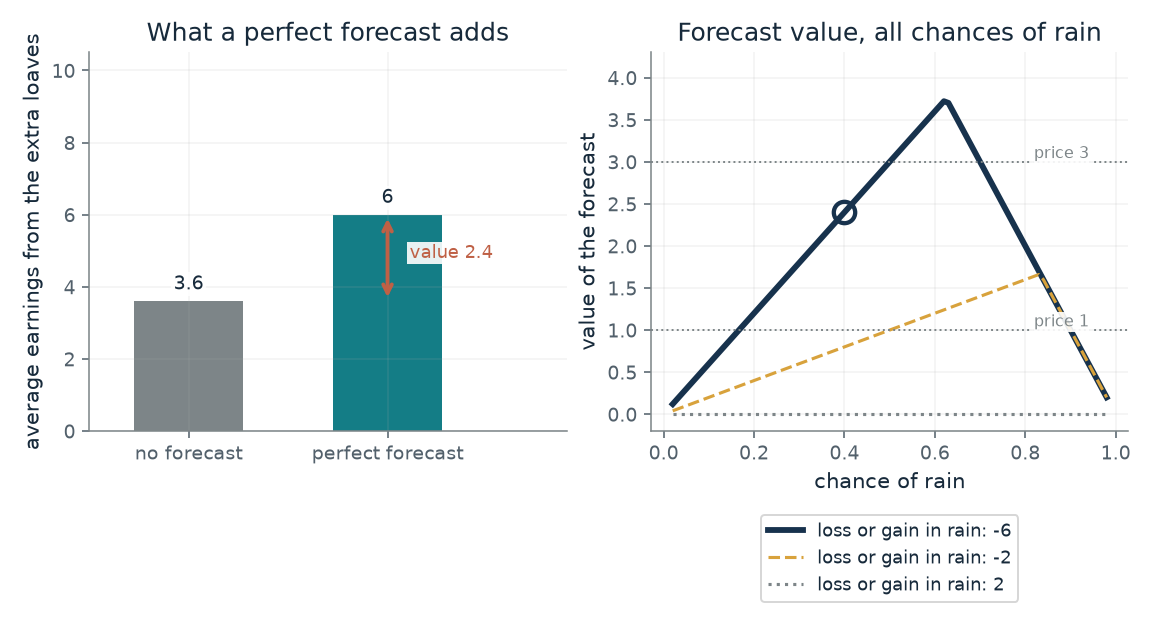

- **Average earnings, no forecast:** 3.6
- **Average earnings, perfect forecast:** 6
- **Value of the forecast (VOC):** 2.4
- **Worth buying at price 1, at price 3:** yes, no

Without a forecast the baker's best average is 3.6; a perfect forecast lifts it to 6, so the forecast is worth 2.4. It is worth buying only at a price below that.

No forecast: max(0, 0.6 x 10 + 0.4 x (-6)) = 3.6. Perfect forecast: 0.6 x 10 + 0.4 x max(0, -6) = 6. VOC = 6 - 3.6 = 2.4.

In [2]:
figure, values, explanation = baker_picture(**{'rain_chance': 0.4, 'rain_payoff': -6})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What is a forecast worth to a baker?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Chance of rain = 0.4, Earnings in the rain = -6: With a 0.4 chance of rain and a loss of 6, the baker earns 3.6 on average without a forecast and 6 with a perfect one, so the forecast is worth 2.4. At a price of 1 it is worth buying and at 3 it is not. Switch the rain payoff to 2 and the value falls to 0.

**Takeaway:** A look is worth what it could improve the decision, and a look that cannot change the best action is worth nothing however accurate it is.

**Why it matters:** A system that gathers more information, computes more or samples again is spending something. Pricing the look against what it could change tells it when to stop.

**In brains and behavior:** Shenhav and colleagues (2013) proposed that a region called the dorsal anterior cingulate cortex works out how hard to try by weighing what effort is likely to bring against its cost. The chapter says this is a theory and review with no new experiment and no value-of-information formula.

**In machines:** In metareasoning, a computation is run only if its expected gain is worth its price. The formula is a specification of that rule; the chapter ties it to the expected value of control, and the model was checked against behavior, not against the cingulate.

**Where it applies:** The price of a look is known and beliefs are revised correctly by Bayes' rule. The forecast is perfect here. The VOC is the gain before the price is subtracted, and looking pays when the gain exceeds the price.

**Check your understanding:** The chance of rain is 0.2 and rain costs 6. What is a perfect forecast worth?

<details><summary>Show the answer</summary>

No forecast: 0.8 x 10 - 0.2 x 6 = 6.8. Perfect forecast: 0.8 x 10 + 0.2 x 0 = 8. The value is 1.2.

</details>

*Source: Chapter 19, A look is worth how much it could improve the decision, minus its price. Book formula and the chapter's made-up baker: 10 if dry, minus 6 if rain, 0 if no extra loaves, chance of rain 0.4, giving 3.6 without a forecast, 6 with a perfect one and a value of 2.4. The changed case (2 in the rain) gives a value of 0. The other chances of rain and the rain payoff of minus 2 are this companion's variations. None of it is data.*

## C19-D02: When do several looks pay although the first does not?

The baker can buy hints about the weather one at a time. When is it worth paying for one, and for more?

The maximum compares two values. Acting now is worth the best average payoff at the current belief. Looking is worth paying c, then getting whatever the best continuation is from the belief after the hint. When one hint cannot flip the baker's decision, the first look looks worthless, but a second hint on the same side can push the belief far enough to skip baking on a day that is probably rainy.

$$
V(p)=\max\left\{U^{*}(p),\,-c+\sum_{x}P(x\mid p)\,V(p_x)\right\}
$$

**Symbols:** p: the current belief that the day will be dry (0.6 to start); U*(p): the best payoff from acting now; c: the price of one look; P(x | p): the chance the hint says x, and p_x the belief after it; V(p): the best payoff when further looks are allowed

**Predict before looking:** With hints right 0.7 of the time and a price of 0.2 per look, predict whether a planner that prices only one look would take any, and whether the best policy would.

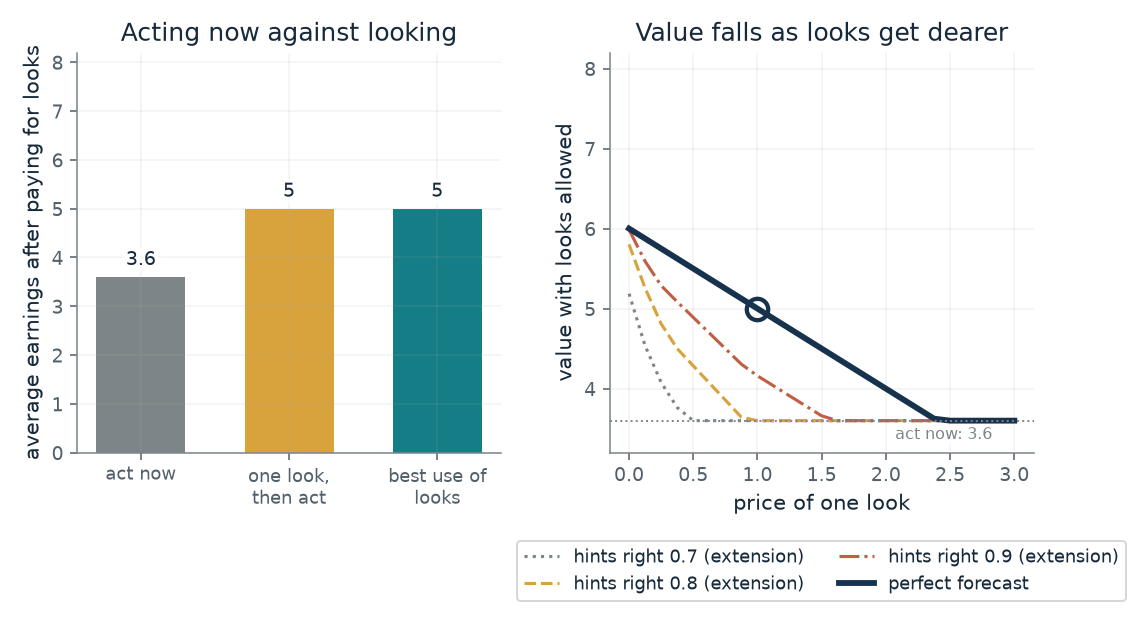

- **Acting now:** 3.6
- **One look then act, minus its price:** 5
- **Best use of looks:** 5
- **Looks expected under the best policy:** 1

With looks costing 1 and a perfect forecast, acting now is worth 3.6, one look then acting 5, and the best use of looks 5. Taking looks pays.

V = max(U*, -c + sum over hints P(hint) V(next)) with at most 8 looks, U* = max(0, 10p - 6(1-p)) and a starting chance of dry 0.6. At the start U* = 0.6 x 10 - 0.4 x 6 = 3.6; V = 5.

In [3]:
figure, values, explanation = looks_picture(**{'cost': 1, 'accuracy': 1.0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='When do several looks pay although the first does not?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Price of one look = 1.0, Chance each hint is right = 1.0: With a perfect forecast costing 1, acting now is worth 3.6 and one look then acting is worth 6 - 1 = 5, so the model takes the look, as in the chapter. Now try hints right 0.7 at a price of 0.2 (the companion's noisy-hint extension, not in the chapter): one look then acting is worth only 3.4, below 3.6, so a planner pricing only the next look declines. The best use of looks is worth 4.2, taking about 3.5 looks.

**Takeaway:** The stopping equation compares acting now with paying for a look and then continuing, and it can find value in several looks that no single look shows.

**Why it matters:** A planner that asks only whether the next look is worth its price can stop before discovering that a few looks together would change the decision.

**In brains and behavior:** The 2013 paper holds no such formula; Lieder and colleagues (2018) argued that choosing which computations to run is formally the metareasoning problem, and checked their model against behavior, not the cingulate.

**In machines:** This is a specification solved by working backward from the last allowed look. A builder supplies the price per look and the number of looks.

**Where it applies:** Known payoffs, a known price per look, hints that are right with the stated chance whatever the weather, Bayes' rule, and at most eight looks. The model needs specified payoffs, observation probabilities and costs. The chapter says when several looks can work together, the first look alone can understate their combined value.

**Check your understanding:** Acting now is worth 3.6, and one look costs 1 and leads to a final payoff of 6 on average. What does the equation take, and what is V?

<details><summary>Show the answer</summary>

Continuing is worth -1 + 6 = 5, above 3.6, so the model takes the look and V = 5.

</details>

*Source: Chapter 19, A look is worth how much it could improve the decision, minus its price. Book equation and the chapter's example: acting now is worth 3.6, and a look costing 1 that leads to an expected final payoff of 6 makes continuing worth 5, so the model takes the look. The perfect forecast is the setting 'a perfect forecast'; the noisy hints (right 0.7, 0.8 or 0.9 of the time), up to eight looks and the other prices are this companion's extension, with the same payoffs.*

## C19-D03: When should a classifier decline to answer?

A page reader costs 0 for a right reading, 2 for a reject and 10 for an error. At what confidence should it answer?

If the reader answers, it is wrong with chance 1 - q and each error costs 10, so answering costs (1 - q) x 10 on average. Declining costs a flat 2. The reader answers when the first is no more than the second. The test is the chance of being right, and a confident answer is kept.

$$
\text{answer if } (1-q)\,c_{\text{error}}\le c_{\text{reject}},\qquad \text{cutoff}=1-\frac{c_{\text{reject}}}{c_{\text{error}}}
$$

**Symbols:** q: the confidence that the best guess is right; c_error: the cost of a wrong answer (10 here); a right answer costs 0; c_reject: the cost of declining and handing the case on; cutoff: the confidence above which answering is cheaper than declining

**Predict before looking:** At a reject cost of 2 and an error cost of 10, predict the lowest confidence at which the reader answers.

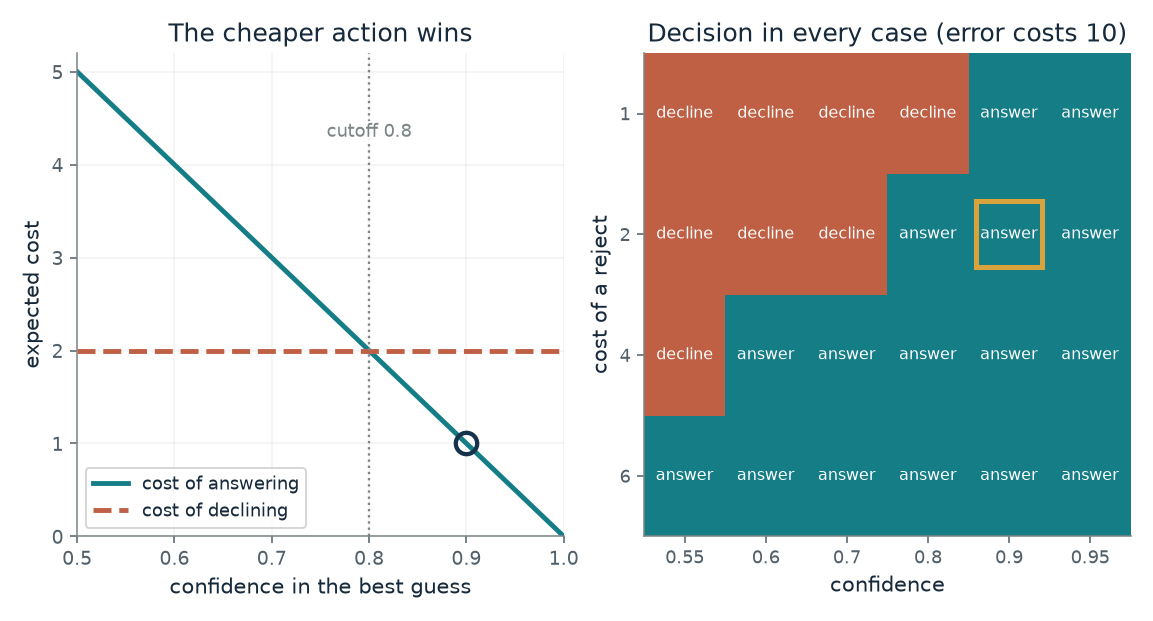

- **Cost of answering:** 1
- **Cost of declining:** 2
- **Decision:** answer
- **Confidence cutoff for answering:** 0.8

At confidence 0.9, answering is wrong 0.1 of the time and costs 1 on average, against 2 for declining, so the reader answers. The cutoff is 1 - 2/10 = 0.8.

Answering costs (1 - 0.9) x 10 = 1. Declining costs 2. Cutoff = 1 - reject cost / error cost = 1 - 2/10 = 0.8.

In [4]:
figure, values, explanation = chow_picture(**{'confidence': 0.9, 'reject_cost': 2})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='When should a classifier decline to answer?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Confidence in the best guess = 0.7, Cost of declining (reject) = 2: At confidence 0.7 answering costs 0.3 x 10 = 3, above the reject cost of 2, so the reader declines. At 0.9 answering costs 1 and it answers. The cutoff is 1 - 2/10 = 0.8.

**Takeaway:** Declining is one more action with a cost, and the reader should take it exactly when answering is expected to cost more.

**Why it matters:** A system that always answers treats every error as free to hand on. Pricing the reject option says when to ask for help.

**In brains and behavior:** Chow's work measures no people.

**In machines:** A classifier that takes its best guess and its confidence can use this rule. The rule is derived for true probabilities, so a badly calibrated confidence makes the rule misfire.

**Where it applies:** A correct answer costs nothing, every error costs the same, and the stated confidence is a calibrated probability. A real system only estimates probabilities, and calibration across a group alone does not ensure the best decision if other known features predict which cases will be wrong. Chow's setting is machine recognition and measures no people.

**Check your understanding:** The reject cost is 4 and the error cost is 10. What is the confidence cutoff, and does a confidence of 0.7 answer?

<details><summary>Show the answer</summary>

The cutoff is 1 - 4/10 = 0.6. At 0.7, answering costs 3, below 4, so it answers.

</details>

*Source: Chapter 19, A classifier could decline when answering costs more than handing the case on. Chow's reject rule (1957, 1970) as the chapter states it, with the chapter's made-up page reader: a correct reading costs 0, a reject 2 and an error 10; confidence 0.9 answers (cost 1 against 2), confidence 0.7 declines (cost 3 against 2), and the cutoff is 0.8. The other reject costs and confidences are this companion's variations.*

## C19-D04: What price on time does a stopping point imply?

A chooser looks at hints one at a time and stops when one answer leads by a fixed amount. What cost per look makes that stopping point best?

A rule that stops at a bound B trades accuracy against time. A larger B makes a right answer likelier but needs more looks, each costing c. The best bound is where one more step of lead no longer buys more accuracy than it costs. Because the value of each bound is a straight line in c, each bound is best over a definite range of costs, and the ranges shrink as the bound grows.

$$
V(B)=P(B)-c\,E[T_B],\quad P(B)=\frac{1}{1+\rho^{B}},\quad E[T_B]=\frac{B\,(2P(B)-1)}{2a-1},\quad \rho=\frac{1-a}{a}
$$

**Symbols:** B: the stopping bound: stop when one answer leads by B net hints; a: the chance each hint points the right way; c: the cost per look, in units of the reward for a right answer; P(B): the chance the answer is right when stopping at bound B; E[T_B]: the average number of looks before stopping

**Predict before looking:** At a cost of 0.01 per look and hints right 0.7 of the time, predict whether the best stopping bound is closer to 1, to 4 or to 10 net hints.

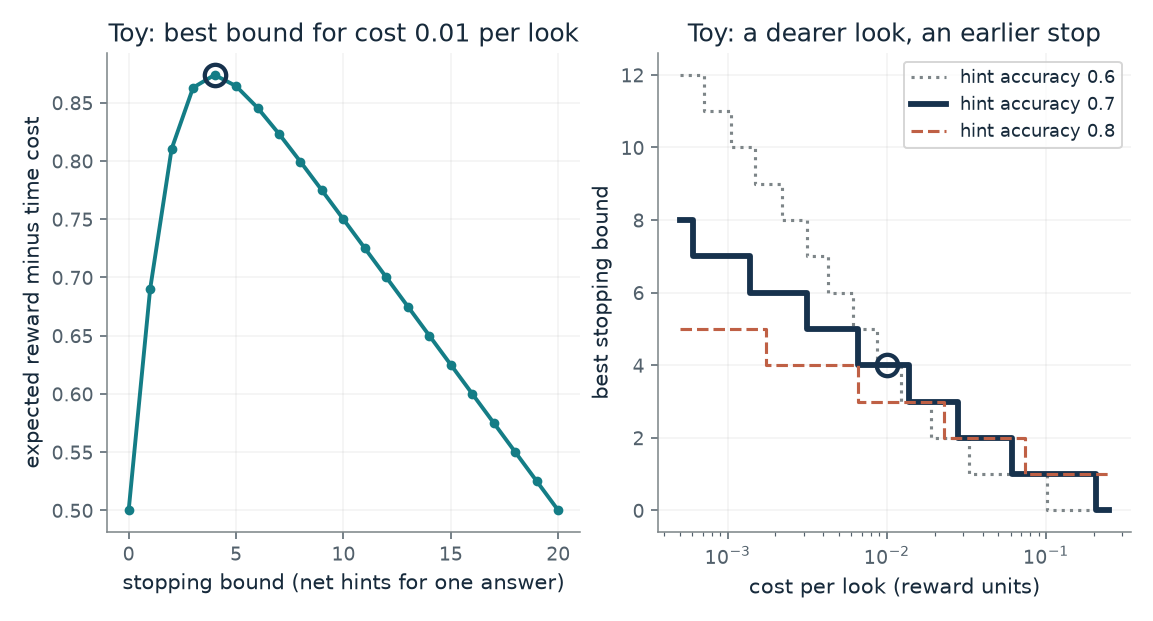

- **Best stopping bound (net hints):** 4
- **Chance the answer is right:** 0.967
- **Looks expected before stopping:** 9.35
- **Costs that make this bound best (backward reading):** 0.00657 to 0.0137

With hints right 0.7 of the time and 0.01 reward per look, stopping once one answer leads by 4 hints is best: chance 0.967 of being right after about 9.35 looks. Stopping there fits a cost per look from 0.00657 to 0.0137, a backward reading that goes beyond the paper.

Value of bound B = P(B) - c x E[looks], P(B) = 1/(1 + rho^B), rho = (1 - a)/a = 0.429, E[looks] = B(2P - 1)/(2a - 1). At B = 4: 0.967 - 0.01 x 9.35 = 0.874.

In [5]:
figure, values, explanation = stopping_picture(**{'cost': 0.01, 'accuracy': 0.7})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What price on time does a stopping point imply?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Cost per look (reward units) = 0.01, Chance each hint is right = 0.7: At 0.01 per look with hints right 0.7 of the time, stopping once one answer leads by 4 net hints is best, with a 0.967 chance of a right answer after about 9.3 looks. Run backward, a chooser who stops at that bound behaves as if each look cost between about 0.0066 and 0.0137. That backward cost range is the companion's extension beyond the paper, with made-up hints and a constant cost.

**Takeaway:** In this toy, a price per look fixes a stopping bound, and a stopping bound fixes the range of prices it is consistent with. The backward range is an extension beyond the paper, not a measured cost of time.

**Why it matters:** The same equation serves both directions. Give a machine a price and it returns a stopping point; watch a stopping point and ask what price it behaves as if it paid.

**In brains and behavior:** Two monkeys and six people stopped on a random-dot task; Drugowitsch and colleagues recovered a cost of time that was neither zero nor constant and rose over a trial, more steeply in the monkeys. The cost is in units of the reward, inferred from a fitted model, not measured.

**In machines:** A builder can set a stopping point by hand, as budget forcing does in the next illustration. That is not a brain mechanism, and it shows the same trade-off.

**Where it applies:** Two equally likely answers, independent hints of the same accuracy, reward 1 for a right answer, 0 for a wrong one, and a constant cost per look. The studies found a cost of time that stayed almost flat at first and then rose, inferred from a fitted model, with only indirect evidence that the subjects maximized reward rate. The toy shows the logic of the inversion, not those results.

**Check your understanding:** With hints right 0.7 and cost 0.2 per look, is any look worth taking?

<details><summary>Show the answer</summary>

No. A single look would raise the chance of a right answer from 0.5 to 0.7, a gain of 0.2 for a cost of 0.2, which is not more than the cost, so the best bound is 0.

</details>

*Source: Chapter 19, When to stop: a rising cost of time, and a model told to Wait. A toy built on the chapter's description of Drugowitsch and colleagues (2012): find the best stopping bound from the price of each look, and run the method the other way, from the stopping to the price. Their model used a diffusion process and dynamic programming on monkeys and people; this toy uses equally likely answers, hints of equal accuracy, a reward of 1 and a constant cost, with closed-form gambler's ruin formulas. All numbers are made up and the chapter says the backward price is an extension beyond the paper.*

## C19-D05: Can a rule that stops at the first deciding cue keep up?

Take The Best checks cues in order and stops at the first one that separates two objects. How does it compare with using every cue, in a made-up world?

Take The Best orders cues by validity and walks down the list until one cue separates the two objects, then stops. It ignores every later cue, so on most pairs it looks at only a few. When the first deciding cue is reliable, the later cues add little. In this constructed world with all nine cues, at high noise a regression fitted in sample to the true sizes did a little better (about 1.5 points at noise 3), while equal-weight tallying did worse. With only three cues Take The Best was level with or ahead of regression at noise 1 to 3.

$$
\text{choose the object with the cue at the first cue } j \text{ (most trusted first) where } x_{aj}\ne x_{bj}
$$

**Symbols:** x_aj: whether object a has cue j (yes or no); validity: of the pairs a cue separates, the share where the object holding the cue is larger; tallying: choose the object with more cues; regression: fit all cues to the true sizes and choose the larger predicted size

**Predict before looking:** Predict whether the gap between Take The Best and a regression that weighs every cue stays small or widens a lot as the cues get noisier.

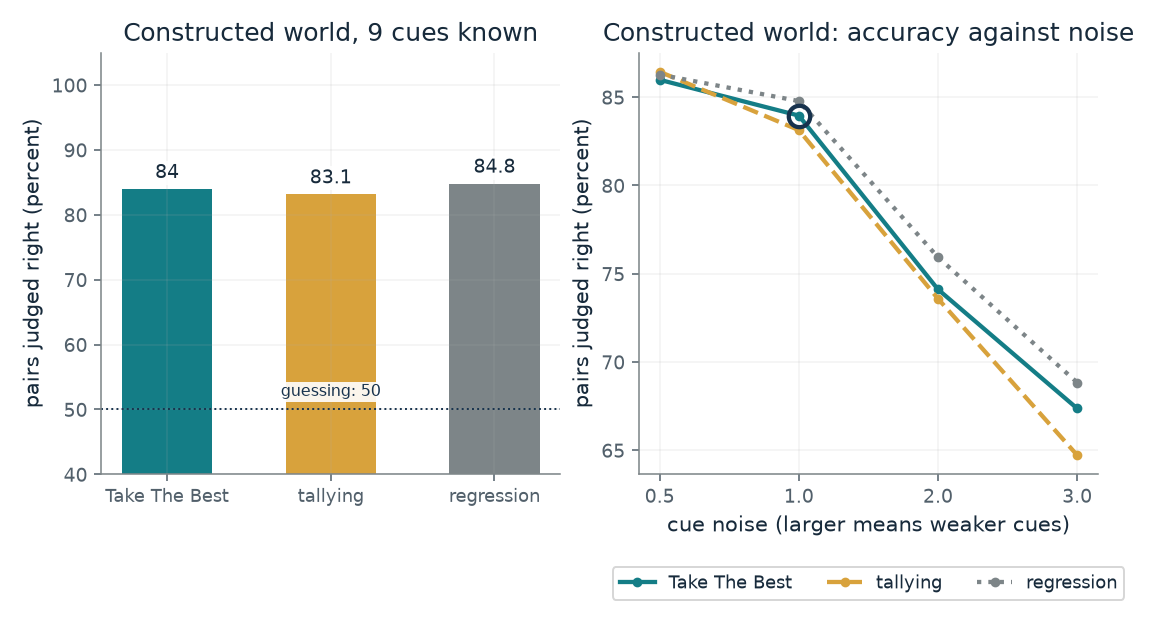

- **Take The Best (percent right):** 84
- **Tallying (percent right):** 83.1
- **Regression (percent right):** 84.8
- **Cues Take The Best looks at, on average:** 2.94

In this made-up world with cue noise 1 and 9 cues known, Take The Best judges 84 percent of the 3,403 pairs right while looking at 2.94 cues on average; tallying gets 83.1 and regression, fitted to the true sizes, 84.8. A constructed simulation, not the paper's cities or a test of people.

Take The Best orders cues by validity (share of the pairs a cue separates where its holder is larger) and stops at the first cue that separates the pair; ties count one half. Seeded world (seed 1996): 83 objects, hidden size, nine cues with prevalences 0.5, 0.45, 0.4, 0.35, 0.3, 0.25, 0.2, 0.15, 0.1.

In [6]:
figure, values, explanation = best_rule_picture(**{'noise': 1.0, 'known_cues': 9})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Can a rule that stops at the first deciding cue keep up?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Cue noise (larger means weaker cues) = 1.0, Cues known = 9: In this constructed world at noise 1 with all nine cues, Take The Best judges 84.0 percent of pairs right against 84.8 for the fitted regression and 83.1 for tallying, while looking at about 2.9 cues per pair. With all nine cues, the gap to regression is about 0.8 points at noise 1, widens to about 1.8 at noise 2 and is about 1.5 at noise 3. The chapter's real result, 65.8 against 65.7 percent, comes from different data.

**Takeaway:** In this constructed world, a rule that stops at the first deciding cue came within about two points of rules that weigh everything, while looking at fewer cues. The chapter's real contest, 65.8 against 65.7, is the paper's own result and is not reproduced here.

**Why it matters:** Stopping is also a design choice: a rule can stop by recipe rather than by pricing each look, and the chapter's examples show it can cost little accuracy in some settings.

**In brains and behavior:** Gigerenzer and Goldstein's contest was a computer simulation, not a test of people.

**In machines:** Take The Best is a fixed recipe. The paper's rule, as the chapter describes it, starts with recognition; this simulation leaves that step out and treats every object as known, then uses the most trusted cue that separates the pair. It compares it with tallying and a fitted regression in a made-up world.

**Where it applies:** Ties count one half. The regression is fitted in sample to the true sizes, a strong rival. The cues track size with noise controlled by a setting. A simulation is a computation with disclosed seeds, never a measurement of people, and the paper's authors call their own result an existence proof that does not show simple rules win in general.

**Check your understanding:** If no cue separates a pair, what does the rule do, and how does this simulation score the pair?

<details><summary>Show the answer</summary>

It guesses; in this simulation a tie is scored as one half of a right answer, so guessing contributes 50 percent on those pairs.

</details>

*Source: Chapter 19, A fixed rule can stop at the first cue that decides. Gigerenzer and Goldstein (1996) as the chapter reports it: 83 German cities, nine cues, 3,403 pairs, Take The Best 65.8 percent against a regression of 65.7, regression favored because it was fitted to the true sizes, 'an existence proof'. This is a different, constructed world built by this companion (83 objects, a hidden size, nine made-up yes-or-no cues of falling prevalence, seed 1996); it does not use the paper's cities or cues and does not reproduce its figures.*

## C19-D06: How big is two problems out of thirty?

A model scored 50.0 percent on a 30-problem math test, and 56.7 percent after budget forcing. How large is that gap, and how would it look on a bigger test?

A test with M problems moves 100/M points with each problem. A score at 50 percent, if each problem were an independent draw, would spread by 100 times the square root of 0.25/M points, which shrinks as the test grows. The chapter's gap is fixed at 6.7 points, so measured against that spread it looks larger on bigger tests.

$$
\text{one problem}=\frac{100}{M}\text{ points},\qquad \mathrm{sd}=100\sqrt{\frac{p(1-p)}{M}},\qquad \text{gap in spreads}=\frac{56.7-50.0}{\sqrt{\mathrm{sd}_1^{2}+\mathrm{sd}_2^{2}}}
$$

**Symbols:** M: the number of problems in the test (30 on AIME24); p: the share of problems solved, 0.500 and 0.567; sd: the spread of a score if each problem were an independent draw at that rate, in points

**Predict before looking:** On a 30-problem test, predict whether a gap of two problems is larger or smaller than one spread of a single score at 50 percent.

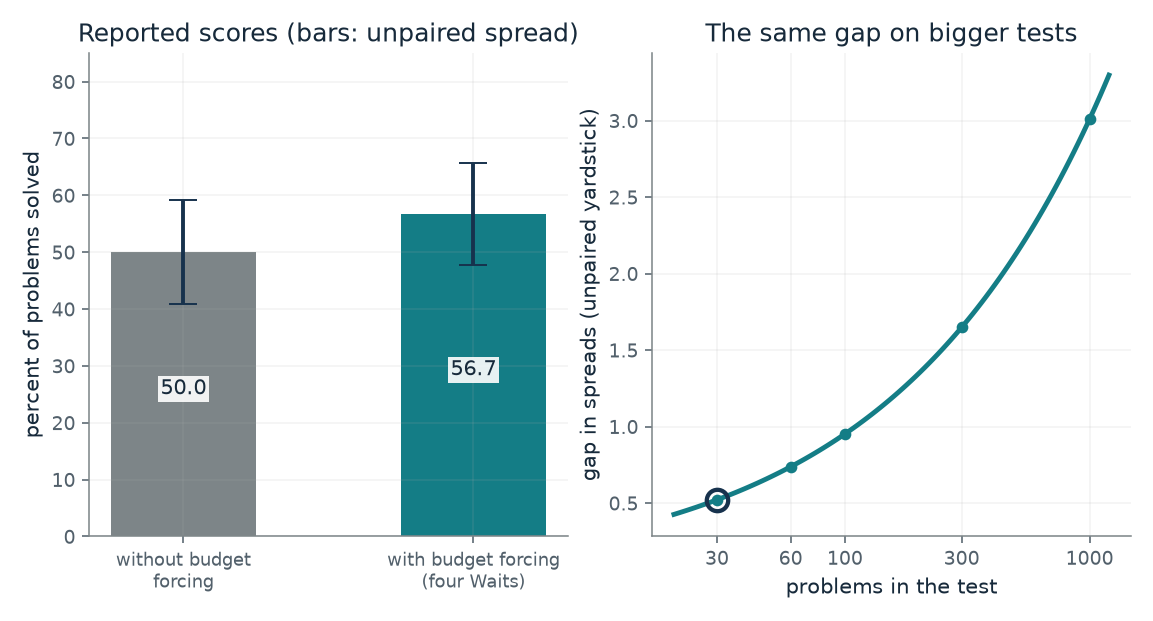

- **Points per problem:** 3.33
- **Problems the 6.7-point gap is worth:** 2
- **Spread of one score (points):** 9.13
- **Gap in spreads of the difference:** 0.521

On 30 problems one problem is 3.33 points, so a 6.7-point gap is about 2 problems. If each problem were an independent draw at 50 percent, one score would spread by about 9.13 points, and the gap would be 0.521 spreads of the difference. Scoring the same problems twice makes this yardstick overstate the noise, so use it for scale only.

Spread of a score = 100 x sqrt(p(1 - p)/30) = 9.13 points at p = 0.5. Spread of a difference = sqrt(9.13^2 + 9.05^2) = 12.9. Gap/spread = 6.7/12.9 = 0.521. If the two scores on the same problems are positively correlated, the true spread of the difference is smaller than this unpaired figure, and the gap would count for more spreads.

In [7]:
figure, values, explanation = budget_picture(**{'problems': 30})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How big is two problems out of thirty?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Problems in the test = 30: On 30 problems one problem is 3.33 points, so the gap is about two problems. A score at 50 percent would spread by about 9.1 points if each problem were an independent draw, and the gap is about half a spread of the difference on this unpaired yardstick, which tends to overstate the noise for scores on the same problems. The same gap on 1,000 problems would be about 3.0 spreads.

**Takeaway:** On a 30-problem test the 6.7-point gap is about two problems. Under an unpaired independent-draw yardstick, which tends to overstate the noise, it is about half a spread of the difference, and the same gap means more on a larger test.

**Why it matters:** A reported gain on a small test deserves a question about its size before a conclusion about its cause. The chapter itself adds that other tests gave smaller and mixed results.

**In brains and behavior:** No brain data are involved. The chapter contrasts this hand-set stopping rule with the fitted cost of time in monkeys and people, and says it is not a brain mechanism.

**In machines:** Budget forcing blocks the end-of-thinking marker and appends 'Wait' to make the model think longer. A builder sets the limit, the same for every question, whatever its difficulty.

**Where it applies:** The yardstick treats each problem as an independent draw at the reported rate and the two scores as independent. The paper's two conditions are scored on the same problems, so this is not its analysis and does not show the gain is or is not real. Because both conditions score the same problems, the true spread of the difference is smaller than this unpaired figure when the two scores are positively correlated, so the yardstick tends to understate how unusual the gap is; the chapter gives no per-problem results, so the size of that effect is not known here. Budget forcing combines length limits and forced continuations, every question got the same limits, and the gain flattened after about six Waits.

**Check your understanding:** On a test of 100 problems, how many problems is a 6.7-point gap?

<details><summary>Show the answer</summary>

One problem is 1 point, so the gap is about 6.7 problems.

</details>

*Source: Chapter 19, When to stop: a rising cost of time, and a model told to Wait. Reported result: Muennighoff and colleagues (2025), s1-32B on AIME24, 30 problems, 50.0 percent without budget forcing and 56.7 percent with budget forcing and four Wait insertions; the chapter notes one problem is worth 3.3 points, so the gap is about two problems, that results on two other tests were smaller and mixed, and that the gain cannot be attributed to the word 'Wait' alone. The spread arithmetic and the bigger test sizes are this companion's yardstick.*

## Bring it to your own question

State the payoffs, the chance of each result and the price of a look. Compute what the look could change before paying for it, check whether it could change the best action at all, and remember that the price is supplied by a builder or a person and the benefit by a model that may leave something out. For a classifier, compute the cost of answering against the cost of declining at the confidence it actually has, and say whether that confidence is calibrated.

Use the `mmi-ch19-spending-thought-wisely` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.